Best Route: [np.int64(1), np.int64(5), np.int64(0), np.int64(4), np.int64(2), np.int64(3), np.int64(1)]
Shortest Distance: 26.83351132609752


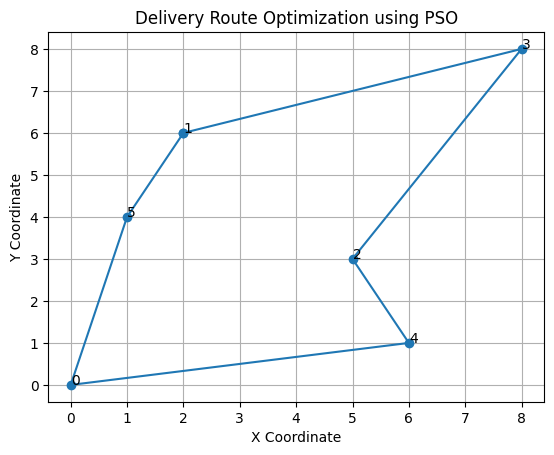

In [1]:
import numpy as np
import matplotlib.pyplot as plt

locations = np.array([
    [0, 0],
    [2, 6],
    [5, 3],
    [8, 8],
    [6, 1],
    [1, 4]
])

n = len(locations)
num_particles = 30
iterations = 100

w = 0.7
c1 = 1.5
c2 = 1.5

def distance(route):
    total = 0
    for i in range(len(route)):
        a = locations[route[i]]
        b = locations[route[(i + 1) % len(route)]]
        total += np.linalg.norm(a - b)
    return total

positions = np.random.rand(num_particles, n)
velocities = np.random.uniform(-1, 1, (num_particles, n))

pbest = positions.copy()
pbest_routes = [np.argsort(p) for p in positions]
pbest_scores = np.array([distance(r) for r in pbest_routes])

gbest_index = np.argmin(pbest_scores)
gbest = pbest[gbest_index].copy()
gbest_route = pbest_routes[gbest_index].copy()
gbest_score = pbest_scores[gbest_index]

for iteration in range(iterations):
    for i in range(num_particles):
        r1 = np.random.rand(n)
        r2 = np.random.rand(n)

        velocities[i] = (
            w * velocities[i]
            + c1 * r1 * (pbest[i] - positions[i])
            + c2 * r2 * (gbest - positions[i])
        )

        positions[i] += velocities[i]

        route = np.argsort(positions[i])
        score = distance(route)

        if score < pbest_scores[i]:
            pbest[i] = positions[i].copy()
            pbest_routes[i] = route.copy()
            pbest_scores[i] = score

        if score < gbest_score:
            gbest = positions[i].copy()
            gbest_route = route.copy()
            gbest_score = score

print("Best Route:", list(gbest_route) + [gbest_route[0]])
print("Shortest Distance:", gbest_score)

route_points = locations[gbest_route]
route_points = np.vstack([route_points, route_points[0]])

plt.plot(route_points[:, 0], route_points[:, 1], 'o-')

for i, point in enumerate(locations):
    plt.text(point[0], point[1], str(i))

plt.title("Delivery Route Optimization using PSO")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid()
plt.show()